<center><h1>Verma_Karan_HW2</h1></center>

**Name:** Karan Verma  
**GitHub Username:** *kv304*  
**USC ID:** *5639810577*

The random seed is fixed so that the 70/30 split can be reproduced.

## 1. Combined Cycle Power Plant Data Set

The response is net hourly electrical output (`PE`). The predictors are ambient temperature (`AT`), exhaust vacuum (`V`), ambient pressure (`AP`), and relative humidity (`RH`). I begin with exploratory analysis and then compare linear, higher-order, and KNN regression.

### (a) Load Sheet 1

In [5]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import statsmodels.api as sm
import statsmodels.formula.api as smf
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsRegressor
from sklearn.preprocessing import PolynomialFeatures, StandardScaler


sns.set_theme(style="whitegrid")
pd.set_option("display.float_format", lambda value: f"{value:,.6f}")

In [6]:
data_path = Path("Folds5x2_pp.xlsx")
power_plant_df = pd.read_excel(data_path, sheet_name="Sheet1")
power_plant_df.head()

,AT,V,AP,RH,PE
0,14.960000,41.760000,"1,024.070000",73.170000,463.260000
1,25.180000,62.960000,"1,020.040000",59.080000,444.370000
2,5.110000,39.400000,"1,012.160000",92.140000,488.560000
3,20.860000,57.320000,"1,010.240000",76.640000,446.480000
4,10.820000,37.500000,"1,009.230000",96.620000,473.900000


I used **Sheet 1**, as required. In the workbook, temperature is labeled `AT` and electrical output is labeled `PE`. Dataset source: [UCI Combined Cycle Power Plant](https://archive.ics.uci.edu/dataset/294/combined+cycle+power+plant).

### (b) Exploring the data

#### (b.i) Dimensions

In [7]:
n_rows, n_columns = power_plant_df.shape
print(f"Rows: {n_rows:,}")
print(f"Columns: {n_columns}")

Rows: 9,568
Columns: 5


The data contain **9,568 observations and 5 variables**. A row is one hourly operating observation. The four ambient measurements are used to predict `PE`. Sheet 1 has no missing values.



In [8]:
#data types of columns
power_plant_df.dtypes.rename("dtype").to_frame()

,dtype
AT,float64
V,float64
AP,float64
RH,float64
PE,float64


In [9]:
#missing value counts for the data
power_plant_df.isna().sum().rename("missing").to_frame()

,missing
AT,0
V,0
AP,0
RH,0
PE,0


#### (b.ii) Pairwise plots

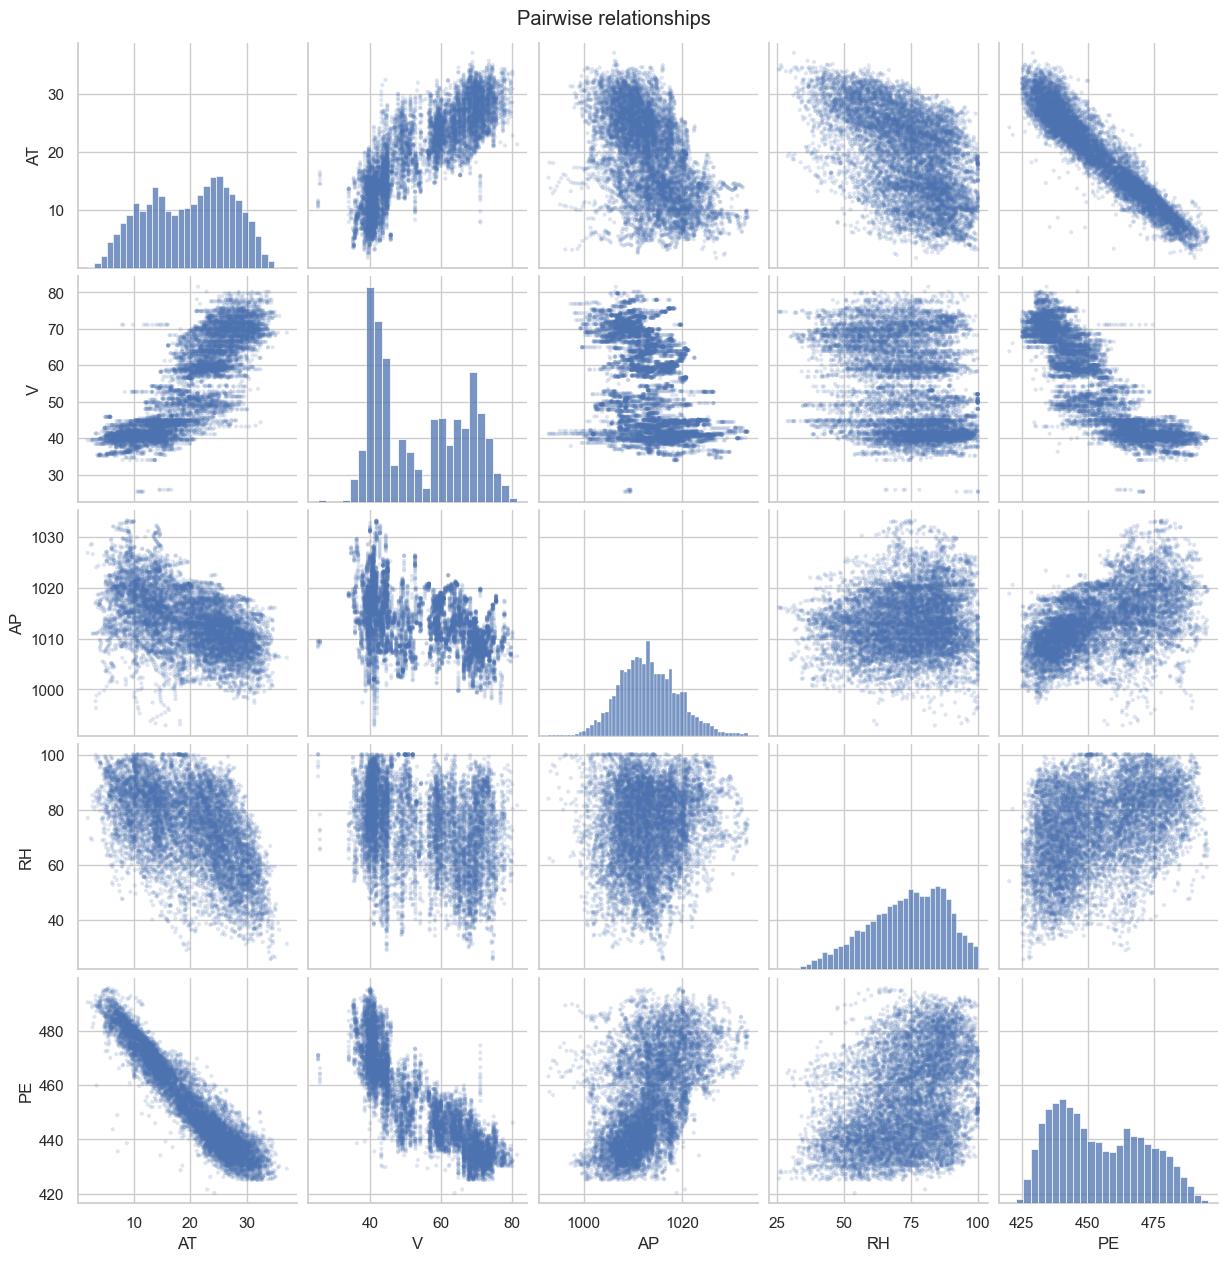

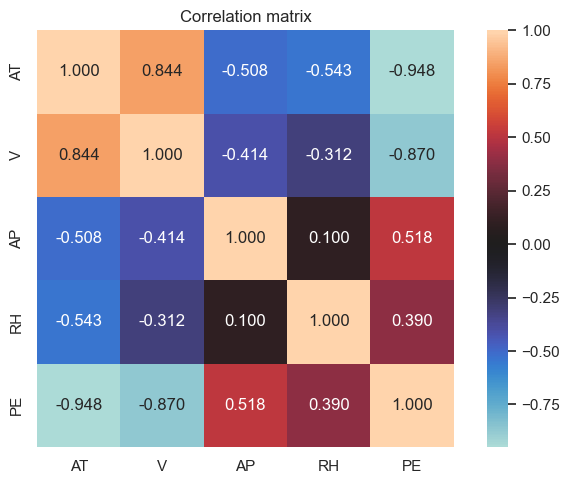

In [10]:
#creating a pairwise plot using seaborn and correlation matrix using pandas
pair_grid = sns.pairplot(
    power_plant_df,
    diag_kind="hist",
    plot_kws={"alpha": 0.18, "s": 9, "edgecolor": "none"},
)
pair_grid.figure.suptitle("Pairwise relationships", y=1.01)
plt.show()

correlation_matrix = power_plant_df.corr(numeric_only=True)
plt.figure(figsize=(7, 5))
sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".3f",
    center=0,
    square=True,
)
plt.title("Correlation matrix")
plt.tight_layout()
plt.show()

The clearest pattern is the negative relationship between output and temperature: the correlation between `PE` and `AT` is about -0.948. `V` also has a strong negative marginal relationship with `PE` (about -0.870). The plots for `AP` and `RH` are weaker and more dispersed. Since `AT` and `V` are themselves correlated, their one-variable slopes should not be interpreted as effects that hold the other conditions fixed. Visible curvature motivates the polynomial models in part (f).

#### (b.iii) Summary statistics

In [11]:
statistical_summary_df = pd.DataFrame(
    {
        "Mean": power_plant_df.mean(),
        "Median": power_plant_df.median(),
        "Minimum": power_plant_df.min(),
        "Maximum": power_plant_df.max(),
        "Range": power_plant_df.max() - power_plant_df.min(),
        "Q1": power_plant_df.quantile(0.25),
        "Q3": power_plant_df.quantile(0.75),
        "IQR": power_plant_df.quantile(0.75) - power_plant_df.quantile(0.25),
    }
)
statistical_summary_df.round(3)

,Mean,Median,Minimum,Maximum,Range,Q1,Q3,IQR
AT,19.651000,20.345000,1.810000,37.110000,35.300000,13.510000,25.720000,12.210000
V,54.306000,52.080000,25.360000,81.560000,56.200000,41.740000,66.540000,24.800000
AP,"1,013.259000","1,012.940000",992.890000,"1,033.300000",40.410000,"1,009.100000","1,017.260000",8.160000
RH,73.309000,74.975000,25.560000,100.160000,74.600000,63.328000,84.830000,21.502000
PE,454.365000,451.550000,420.260000,495.760000,75.500000,439.750000,468.430000,28.680000


The range uses the two extremes. The IQR equals `Q3 - Q1`, so it describes the spread of the middle half of the observations and is less affected by extreme values.

### (c) Simple linear regressions

For each predictor, I fit `PE = beta0 + beta1 X + error`. The slope is the estimated change in mean output associated with a one-unit increase in that predictor. Its p-value tests whether the marginal linear association is zero.

In [12]:
RANDOM_SEED = 42
ALPHA = 0.05
PREDICTORS = ["AT", "V", "AP", "RH"]
RESPONSE = "PE"

In [13]:
#simple_models stores the complete fitted model for each predictor.
#simple_rows collects ordinary linear regression results.
#influence_rows collects outlier and influence diagnostics.

simple_models = {}
simple_rows = []
influence_rows = []

#iterating to fit individual models using statsmodel library
for predictor in PREDICTORS:
    model = smf.ols(f"{RESPONSE} ~ {predictor}", data=power_plant_df).fit()
    simple_models[predictor] = model

    # diagnosing influence of each observation on the model response results
    influence = model.get_influence()
    studentized = influence.resid_studentized_internal
    cooks_distance = influence.cooks_distance[0]

    # Adding individual model stats with each pass through the loop 
    simple_rows.append(
        {
            "Predictor": predictor,
            "Intercept": model.params["Intercept"],
            "Slope": model.params[predictor],
            "P-value": model.pvalues[predictor],
            "R2": model.rsquared,
            "MSE": np.mean(model.resid**2),
        }
    )

    #finding The largest absolute studentized residual found in the model and The number of observations 
    #  - with absolute studentized residuals above 3 
    #  - with Cook’s distance above the heuristic 4/n.
	
    influence_rows.append(
        {
            "Predictor": predictor,
            "|studentized| > 3": np.sum(np.abs(studentized) > 3),
            "Cook D > 4/n": np.sum(cooks_distance > 4 / len(power_plant_df)),
            "Max |studentized|": np.max(np.abs(studentized)),
        }
    )


simple_results = pd.DataFrame(simple_rows).set_index("Predictor")
influence_summary = pd.DataFrame(influence_rows).set_index("Predictor")

In [14]:
simple_results

,Intercept,Slope,P-value,R2,MSE
Predictor,,,,,
AT,497.034120,-2.171320,0.000000,0.898948,29.431702
V,517.801526,-1.168135,0.000000,0.756518,70.914651
AP,"-1,055.260989",1.489872,0.000000,0.268769,212.972500
RH,420.961766,0.455650,0.000000,0.151939,246.999228


In [15]:
influence_summary

,|studentized| > 3,Cook D > 4/n,Max |studentized|
Predictor,,,
AT,42,416,8.470861
V,33,423,4.745373
AP,29,300,4.130209
RH,2,249,3.022245


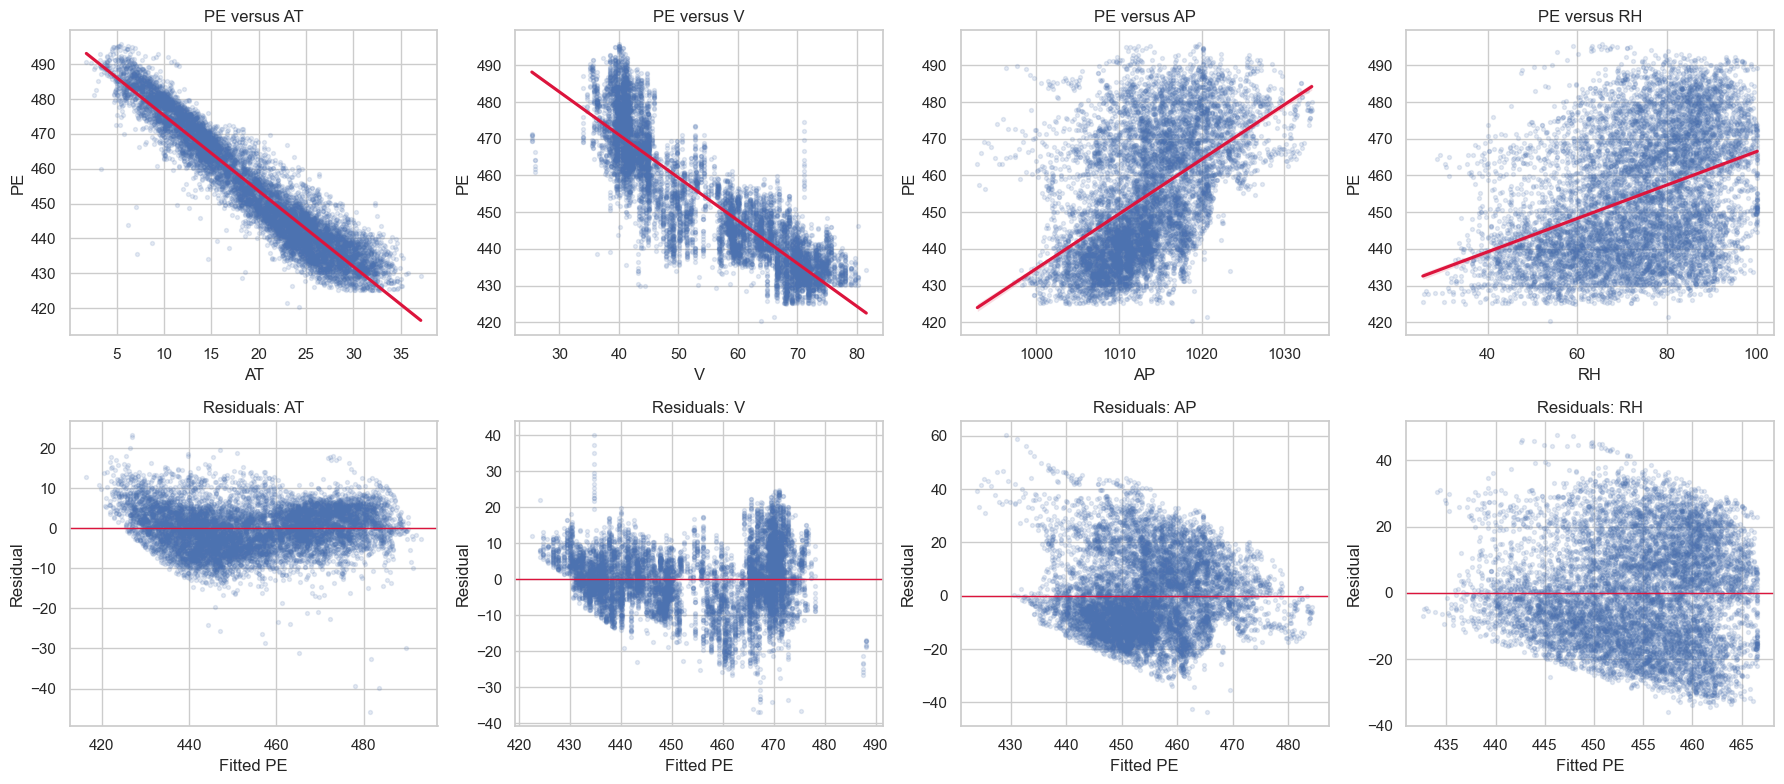

In [16]:
figure, axes = plt.subplots(2, len(PREDICTORS), figsize=(18, 8))

#linearity visualization of predictors with response variable
for column, predictor in enumerate(PREDICTORS):
    model = simple_models[predictor]
    sns.regplot(
        data=power_plant_df,
        x=predictor,
        y=RESPONSE,
        scatter_kws={"alpha": 0.15, "s": 8},
        line_kws={"color": "crimson"},
        ax=axes[0, column],
    )
    axes[0, column].set_title(f"PE versus {predictor}")
    axes[1, column].scatter(model.fittedvalues, model.resid, alpha=0.15, s=8)
    axes[1, column].axhline(0, color="crimson", linewidth=1)
    axes[1, column].set_xlabel("Fitted PE")
    axes[1, column].set_ylabel("Residual")
    axes[1, column].set_title(f"Residuals: {predictor}")

plt.tight_layout()
plt.show()

All four simple-regression slopes have p-values below 0.05. `AT` is the strongest single linear predictor, with R-squared near 0.899, followed by `V`, with R-squared near 0.757. The residual plots show curvature and some large residuals. I would inspect influential observations, but I would not delete them only because a one-predictor model fits them poorly; they may be valid operating conditions that require a richer model.

### (d) Multiple regression

In [17]:
#creating an R based string for statsmodel
multiple_formula = f"{RESPONSE} ~ " + " + ".join(PREDICTORS)
multiple_model = smf.ols(multiple_formula, data=power_plant_df).fit()
multiple_results = pd.DataFrame(
    {
        "Coefficient": multiple_model.params,
        "Std. Error": multiple_model.bse,
        "t-statistic": multiple_model.tvalues,
        "P-value": multiple_model.pvalues,
    }
)
display(multiple_results)
print(f"R-squared: {multiple_model.rsquared:.6f}")
print(f"Training MSE: {np.mean(multiple_model.resid**2):.6f}")

,Coefficient,Std. Error,t-statistic,P-value
Intercept,454.609274,9.748512,46.633709,0.000000
AT,-1.977513,0.015289,-129.342024,0.000000
V,-0.233916,0.007282,-32.122109,0.000000
AP,0.062083,0.009458,6.564086,0.000000
RH,-0.158054,0.004168,-37.918473,0.000000


R-squared: 0.928696
Training MSE: 20.767398


At the 5% level, I reject `H0: beta_j = 0` for all four predictors. The model explains about 92.87% of the observed variation in `PE`. Holding the other variables fixed, the estimated coefficients of `AT`, `V`, and `RH` are negative, whereas the coefficient of `AP` is positive.

### (e) Simple versus multiple coefficients

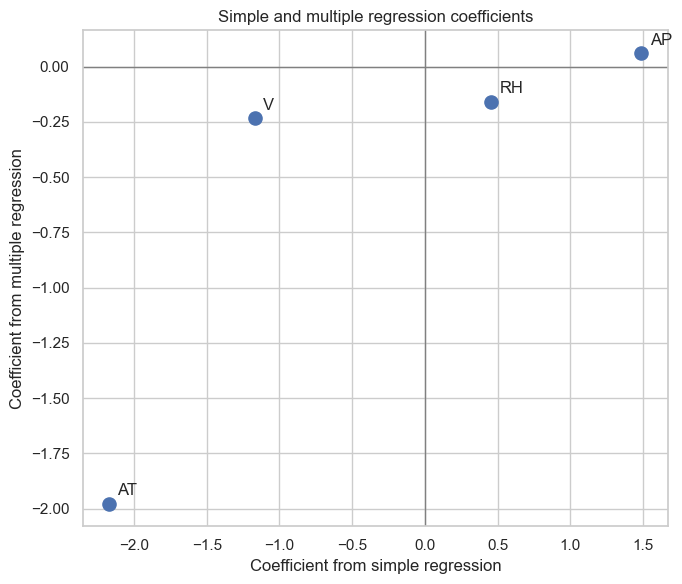

,Simple,Multiple
AT,-2.171320,-1.977513
V,-1.168135,-0.233916
AP,1.489872,0.062083
RH,0.455650,-0.158054


In [18]:
coefficient_comparison = pd.DataFrame(
    {
        "Simple": [simple_models[name].params[name] for name in PREDICTORS],
        "Multiple": [multiple_model.params[name] for name in PREDICTORS],
    },
    index=PREDICTORS,
)

plt.figure(figsize=(7, 6))
plt.axhline(0, color="gray", linewidth=1)
plt.axvline(0, color="gray", linewidth=1)
plt.scatter(coefficient_comparison["Simple"], coefficient_comparison["Multiple"], s=90)
for predictor, estimates in coefficient_comparison.iterrows():
    plt.annotate(
        predictor,
        (estimates["Simple"], estimates["Multiple"]),
        xytext=(6, 6),
        textcoords="offset points",
    )
plt.xlabel("Coefficient from simple regression")
plt.ylabel("Coefficient from multiple regression")
plt.title("Simple and multiple regression coefficients")
plt.tight_layout()
plt.show()
display(coefficient_comparison)

The coefficients differ because the predictors are correlated. A simple coefficient describes a marginal relationship with `PE`; a multiple coefficient describes the relationship after holding the remaining predictors fixed. `RH` gives the clearest example because its estimated sign changes.

### (f) Nonlinear associations

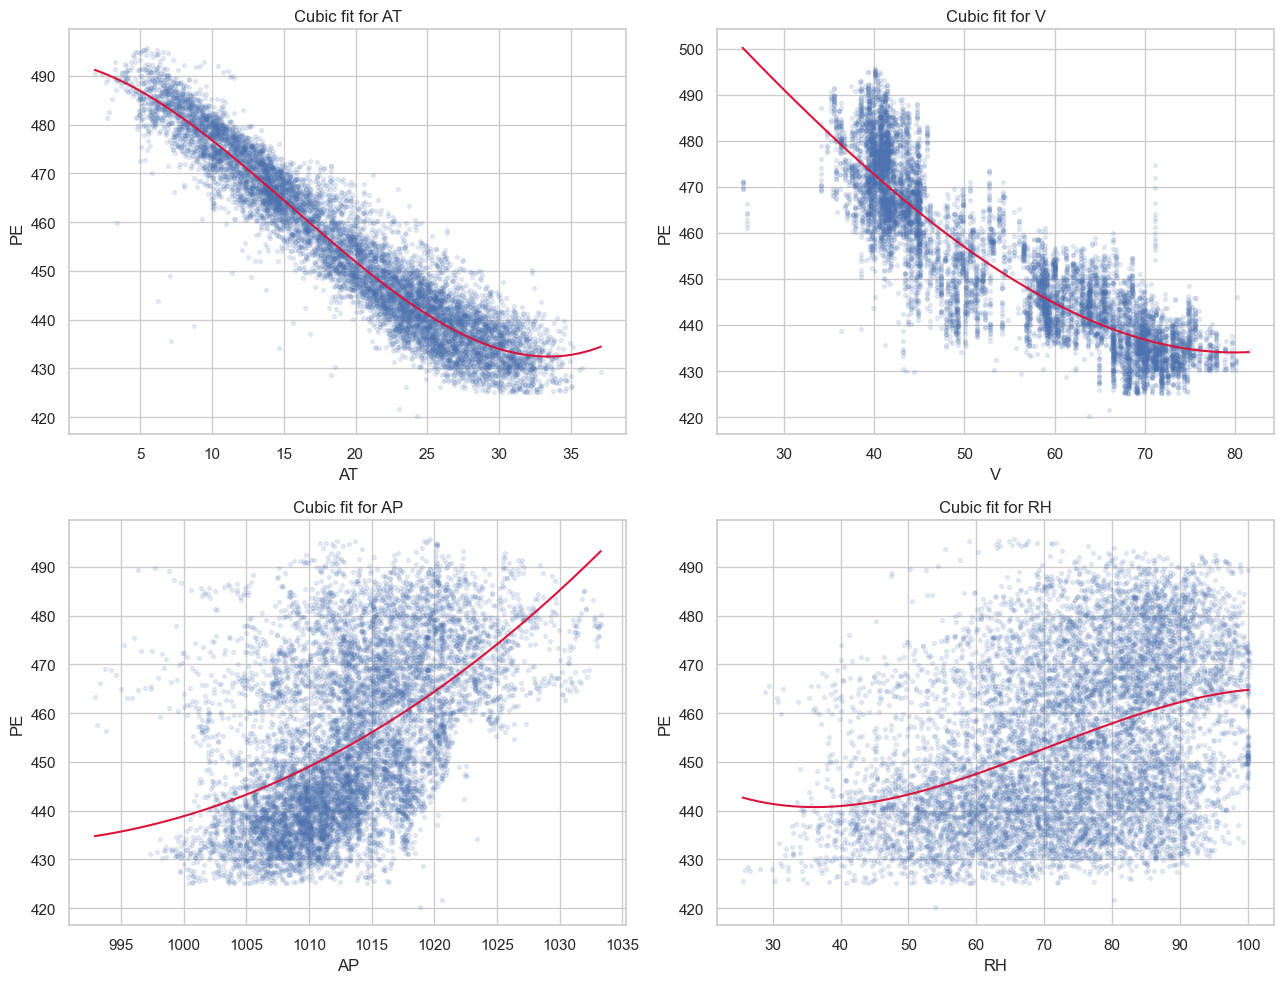

,p(linear),p(quadratic),p(cubic),R2
Predictor,,,,
AT,0.000001,0.000000,0.000000,0.911883
V,0.000025,0.768497,0.013735,0.775022
AP,0.000000,0.000000,0.000000,0.274863
RH,0.000377,0.000009,0.000014,0.153743


In [19]:
nonlinear_rows = []
figure, axes = plt.subplots(2, 2, figsize=(13, 10))

for axis, predictor in zip(axes.ravel(), PREDICTORS):
    cubic_formula = (
        f"{RESPONSE} ~ {predictor} + I({predictor}**2) + I({predictor}**3)"
    )
    cubic_model = smf.ols(cubic_formula, data=power_plant_df).fit()
    grid = np.linspace(power_plant_df[predictor].min(), power_plant_df[predictor].max(), 250)

    nonlinear_rows.append(
        {
            "Predictor": predictor,
            "p(linear)": cubic_model.pvalues[predictor],
            "p(quadratic)": cubic_model.pvalues[f"I({predictor} ** 2)"],
            "p(cubic)": cubic_model.pvalues[f"I({predictor} ** 3)"],
            "R2": cubic_model.rsquared,
        }
    )
    axis.scatter(power_plant_df[predictor], power_plant_df[RESPONSE], alpha=0.13, s=8)
    axis.plot(
        grid,
        cubic_model.predict(pd.DataFrame({predictor: grid})),
        color="crimson",
    )
    axis.set_title(f"Cubic fit for {predictor}")
    axis.set_xlabel(predictor)
    axis.set_ylabel(RESPONSE)

plt.tight_layout()
plt.show()
nonlinear_results = pd.DataFrame(nonlinear_rows).set_index("Predictor")
display(nonlinear_results)

Each predictor has evidence of nonlinearity because at least one second- or third-order term is significant at 5%. The evidence is especially clear for `AT`, `AP`, and `RH`. For `V`, the cubic term is significant even though the quadratic term is not. These curves should not be extrapolated beyond the observed ranges.

### (g) Pairwise interactions

In [20]:
interaction_formula = f"{RESPONSE} ~ (" + " + ".join(PREDICTORS) + ")**2"
interaction_model = smf.ols(interaction_formula, data=power_plant_df).fit()
interaction_terms = ["AT:V", "AT:AP", "AT:RH", "V:AP", "V:RH", "AP:RH"]
interaction_results = pd.DataFrame(
    {
        "Coefficient": interaction_model.params[interaction_terms],
        "P-value": interaction_model.pvalues[interaction_terms],
    }
)
interaction_results["Significant at 5%"] = interaction_results["P-value"] < ALPHA
display(interaction_results)

,Coefficient,P-value,Significant at 5%
AT:V,0.020971,0.000000,True
AT:AP,0.001759,0.452051,False
AT:RH,-0.005230,0.000000,True
V:AP,0.006812,0.000000,True
V:RH,0.000839,0.086194,False
AP:RH,-0.001612,0.033606,True


At 5%, the significant interactions are `AT:V`, `AT:RH`, `V:AP`, and `AP:RH`. The terms `AT:AP` and `V:RH` are not significant. A significant interaction indicates that the estimated association between one predictor and output depends on another predictor.

### (h) Model improvement

I use one random 70/30 split for both model classes. The expanded linear model starts with the main effects, squared terms, and all two-way interactions. Backward elimination is applied only to the higher-order terms; all main effects are retained to respect hierarchy.

In [21]:
#storing all features and target variables
features = power_plant_df[PREDICTORS]
target = power_plant_df[RESPONSE]

# train test split of data at 70% ratio
X_train, X_test, y_train, y_test = train_test_split(
    features,
    target,
    test_size=0.30,
    random_state=RANDOM_SEED,
)

#training a baseline OLS model over current features
baseline_train_design = sm.add_constant(X_train, has_constant="add")
baseline_test_design = sm.add_constant(X_test, has_constant="add")
baseline_model = sm.OLS(y_train, baseline_train_design).fit()

#creating quadratic and interaction features. Naming them with approriate titles
quadratic_builder = PolynomialFeatures(degree=2, include_bias=False)
expanded_train = pd.DataFrame(
    quadratic_builder.fit_transform(X_train),
    columns=quadratic_builder.get_feature_names_out(PREDICTORS),
    index=X_train.index,
)

# using the same quad builder, transforming the test set
expanded_test = pd.DataFrame(
    quadratic_builder.transform(X_test),
    columns=quadratic_builder.get_feature_names_out(PREDICTORS),
    index=X_test.index,
)



def backward_select_higher_order(design_training_data, response, required_terms, alpha=0.05):
    """Remove optional terms one at a time while preserving all main effects."""

    #stores list of expanded and base features to be reatained or removed based on p-Value threshold in alpha
    retained_terms = list(design_training_data.columns)
    required_terms = set(required_terms)

    #running a loop till No optional terms remain OR Every remaining optional term has a p-value no greater than  alpha .
    while True:
        current_training_data = sm.add_constant(
            design_training_data[retained_terms],
            has_constant="add",
        )
        fitted_model = sm.OLS(response, current_training_data).fit()
        optional_pvalues = fitted_model.pvalues.drop("const").drop(
            labels=list(required_terms),
            errors="ignore",
        )
        if optional_pvalues.empty or optional_pvalues.max() <= alpha:
            return fitted_model, retained_terms

        # only remove the max p-value feature/term and continue to recalculate p-values    
        retained_terms.remove(optional_pvalues.idxmax())


#The function returns: The final fitted model and names of the features that survived selection.
selected_model, selected_terms = backward_select_higher_order(
    expanded_train,
    y_train,
    required_terms=PREDICTORS,
    alpha=ALPHA,
)


#baseline model predictions on train and test set
baseline_train_predictions = baseline_model.predict(baseline_train_design)
baseline_test_predictions = baseline_model.predict(baseline_test_design)

#selected model predictions on train and test set
selected_train_predictions = selected_model.predict(
    sm.add_constant(expanded_train[selected_terms], has_constant="add")
)
selected_test_predictions = selected_model.predict(
    sm.add_constant(expanded_test[selected_terms], has_constant="add")
)

#comparing results on both models
linear_model_comparison = pd.DataFrame(
    {
        "Train MSE": [
            mean_squared_error(y_train, baseline_train_predictions),
            mean_squared_error(y_train, selected_train_predictions),
        ],
        "Test MSE": [
            mean_squared_error(y_test, baseline_test_predictions),
            mean_squared_error(y_test, selected_test_predictions),
        ],
    },
    index=["Baseline linear", "Selected quadratic/interactions"],
)
print("Terms retained in the expanded model:")
print(selected_terms)
display(linear_model_comparison)

Terms retained in the expanded model:
['AT', 'V', 'AP', 'RH', 'AT^2', 'AT V', 'AT AP', 'AT RH', 'AP^2', 'AP RH', 'RH^2']


,Train MSE,Test MSE
Baseline linear,20.580840,21.239857
Selected quadratic/interactions,17.890843,18.660040


With this split, the baseline linear model has train/test MSEs of approximately **20.58/21.24**. The selected higher-order model reduces them to approximately **17.89/18.66**. The lower test MSE indicates better prediction on held-out observations, not only improved fit to the training data.

### (i) KNN regression

KNN predicts by averaging nearby training responses. A small `k` gives a flexible fit, while a large `k` smooths over more observations. Since Euclidean distance depends on measurement scale, I evaluate raw and standardized predictors. The scaler is estimated only from the training set.

In [22]:
#creating distance uniformity for finding neighbors
standardizer = StandardScaler()
X_train_scaled = standardizer.fit_transform(X_train)
X_test_scaled = standardizer.transform(X_test)

feature_versions = {
    "Raw": (X_train.to_numpy(), X_test.to_numpy()),
    "Normalized": (X_train_scaled, X_test_scaled),
}

# creating multiple KNN models with different flexibilities.
knn_rows = []
for feature_label, (training_features, testing_features) in feature_versions.items():
    for n_neighbors in range(1, 101):
        knn_model = KNeighborsRegressor(n_neighbors=n_neighbors)
        knn_model.fit(training_features, y_train)
        knn_rows.append(
            {
                "Features": feature_label,
                "k": n_neighbors,
                "1/k": 1 / n_neighbors,
                "Train MSE": mean_squared_error(
                    y_train,
                    knn_model.predict(training_features),
                ),
                "Test MSE": mean_squared_error(
                    y_test,
                    knn_model.predict(testing_features),
                ),
            }
        )

knn_results = pd.DataFrame(knn_rows)
best_knn = knn_results.loc[
    knn_results.groupby("Features")["Test MSE"].idxmin()
]

In [23]:
best_knn

,Features,k,1/k,Train MSE,Test MSE
103,Normalized,4,0.250000,8.591433,14.305669
4,Raw,5,0.200000,10.600769,15.726820


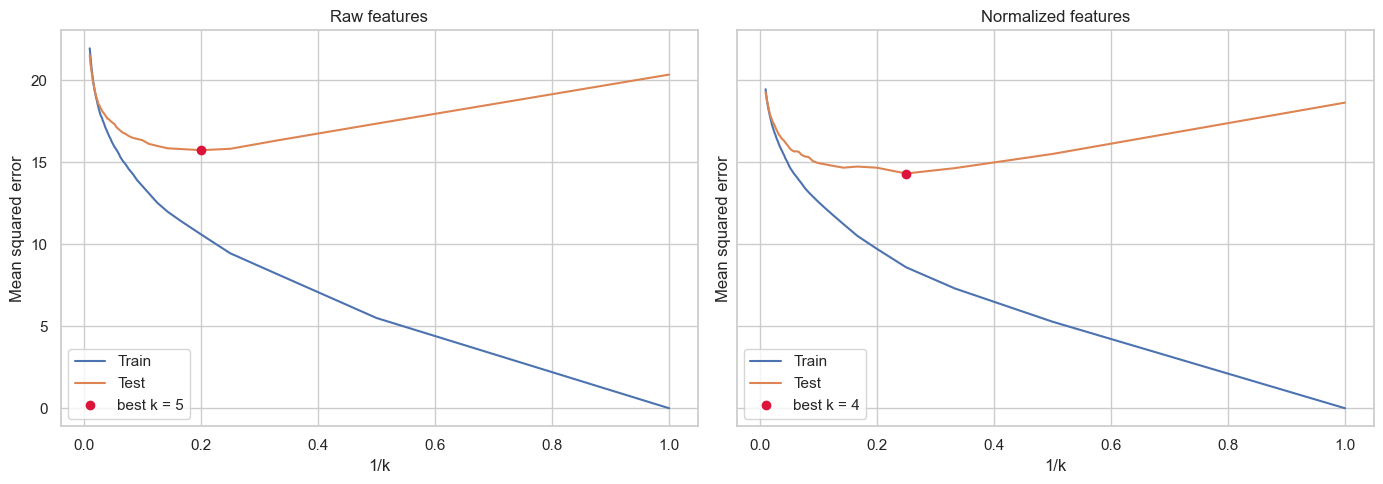

In [24]:
figure, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)

#visualising raw vs scaled feature results
for axis, feature_label in zip(axes, ["Raw", "Normalized"]):
    subset = knn_results.loc[
        knn_results["Features"] == feature_label
    ].sort_values("1/k")
    optimum = best_knn.loc[best_knn["Features"] == feature_label].iloc[0]
    axis.plot(subset["1/k"], subset["Train MSE"], label="Train")
    axis.plot(subset["1/k"], subset["Test MSE"], label="Test")
    axis.scatter(
        1 / optimum["k"],
        optimum["Test MSE"],
        color="crimson",
        label=f"best k = {int(optimum['k'])}",
        zorder=3,
    )
    axis.set_title(f"{feature_label} features")
    axis.set_xlabel("1/k")
    axis.set_ylabel("Mean squared error")
    axis.legend()

plt.tight_layout()
plt.show()

For the raw predictors, the lowest test MSE occurs at `k=5` and is about **15.73**. After standardization, the best value is `k=4`, with test MSE about **14.31**. The improvement is consistent with unscaled Euclidean distance being influenced by variables with larger numerical ranges.

### (j) Comparison

,Train MSE,Test MSE
Baseline linear,20.580840,21.239857
Selected higher-order,17.890843,18.660040
KNN raw,10.600769,15.726820
KNN normalized,8.591433,14.305669


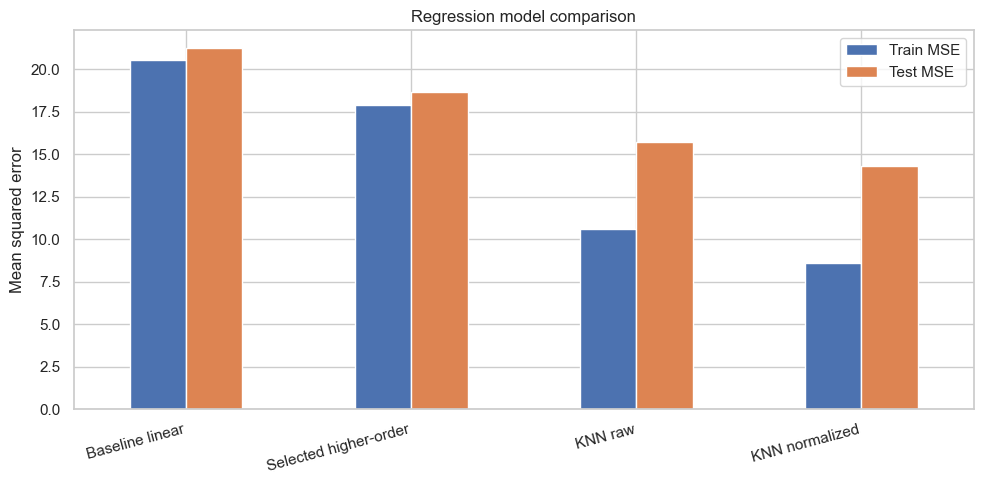

In [25]:
best_knn_by_features = best_knn.set_index("Features")
model_comparison = pd.DataFrame(
    {
        "Train MSE": [
            linear_model_comparison.loc["Baseline linear", "Train MSE"],
            linear_model_comparison.loc["Selected quadratic/interactions", "Train MSE"],
            best_knn_by_features.loc["Raw", "Train MSE"],
            best_knn_by_features.loc["Normalized", "Train MSE"],
        ],
        "Test MSE": [
            linear_model_comparison.loc["Baseline linear", "Test MSE"],
            linear_model_comparison.loc["Selected quadratic/interactions", "Test MSE"],
            best_knn_by_features.loc["Raw", "Test MSE"],
            best_knn_by_features.loc["Normalized", "Test MSE"],
        ],
    },
    index=["Baseline linear", "Selected higher-order", "KNN raw", "KNN normalized"],
)
display(model_comparison)
model_comparison.plot.bar(figsize=(10, 5))
plt.ylabel("Mean squared error")
plt.xticks(rotation=15, ha="right")
plt.title("Regression model comparison")
plt.tight_layout()
plt.show()

For this split, standardized KNN has the smallest test MSE. This suggests that nearby operating conditions contain predictive structure not fully represented by the global polynomial model. The higher-order regression is easier to interpret because its coefficients can be examined directly; KNN predicts better here but does not provide one regression equation.

## 2. ISLR 2.4.1

**(a) Large n and small p:** A flexible method is likely to perform better because there are enough observations to estimate a more complicated relationship without an excessive variance increase.

**(b) Large p and small n:** A flexible method is likely to perform worse because it can fit noise. A less flexible or regularized method is safer.

**(c) Highly nonlinear relationship:** A flexible method should perform better because a rigid linear model would have substantial bias.

**(d) High error variance:** A flexible method should perform worse because it is more likely to chase irreducible noise, increasing variance without recovering signal.

## 3. ISLR 2.4.7

The test point is `(0, 0, 0)`.

In [26]:
# synthesising the mentioned dataframe
islr_knn_data = pd.DataFrame(
    {
        "Observation": [1, 2, 3, 4, 5, 6],
        "X1": [0, 2, 0, 0, -1, 1],
        "X2": [3, 0, 1, 1, 0, 1],
        "X3": [0, 0, 3, 2, 1, 1],
        "Y": ["Red", "Red", "Red", "Green", "Green", "Red"],
    }
)
#creating distance measurement of x1,x2,x3 from (0,0,0)
coordinate_columns = ["X1", "X2", "X3"]
islr_knn_data["Distance to (0,0,0)"] = np.sqrt(
    (islr_knn_data[coordinate_columns] ** 2).sum(axis=1)
)

#rearranging from shortest to farthest
islr_knn_data.sort_values("Distance to (0,0,0)")

,Observation,X1,X2,X3,Y,"Distance to (0,0,0)"
4,5,-1,0,1,Green,1.414214
5,6,1,1,1,Red,1.732051
1,2,2,0,0,Red,2.000000
3,4,0,1,2,Green,2.236068
0,1,0,3,0,Red,3.000000
2,3,0,1,3,Red,3.162278


**(a)** The Euclidean distances for observations 1 through 6 are `3`, `2`, `sqrt(10)`, `sqrt(5)`, `sqrt(2)`, and `sqrt(3)`, respectively.

**(b)** For `K=1`, observation 5 is closest. Its class is Green, so the prediction is **Green**.

**(c)** For `K=3`, the nearest observations are 5 (Green), 6 (Red), and 2 (Red). The majority class is **Red**.

**(d)** If the Bayes boundary is highly nonlinear, a **small K** is usually preferable. A small neighborhood can follow local changes, whereas a large K produces a smoother, less flexible boundary.

## Notes from the analysis

The main distinction used throughout the assignment is between explanation and prediction. Regression coefficients and p-values describe associations, whereas held-out MSE evaluates prediction. The comparison also shows why correlated predictors change coefficient interpretation and why scaling matters for a distance-based method.